# FLANG-RoBERTa S&P 100 Cosine Stock Selector (Kaggle)

Fine-tune a shared FLANG-RoBERTa encoder on news/company pairs. At inference, embed each article and every S&P 100 ticker/company profile, then rank the full universe by cosine similarity. The model has no fixed ticker-class head, so ticker labels absent from the annotations remain candidates.

Attach `financial_news_ticker_linking.csv` as a Kaggle Input and enable Internet for the first FLANG-RoBERTa download. The notebook uses a temporal headline-grouped train/validation/test split, prints and plots held-out top-K metrics, exports a Kaggle-ready bundle, and includes a Kaggle Models upload cell.


## Dependencies

Run the install cell first. Enable a Kaggle GPU accelerator for fine-tuning.


In [1]:
%pip -q install -U "transformers<5" sentencepiece kagglehub


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 90.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 71.5 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import ast, json, math, random, re, copy

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoModel, AutoTokenizer
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type != "cuda":
    print("Warning: no GPU detected. Training on CPU will be slow; enable a Kaggle GPU accelerator.")
print("Device:", DEVICE)

INPUT_ROOT = Path("/kaggle/input")
DATA_MATCHES = list(INPUT_ROOT.rglob("financial_news_ticker_linking.csv"))
if not DATA_MATCHES:
    raise FileNotFoundError("Attach financial_news_ticker_linking.csv as a Kaggle Input.")
DATA_PATH = DATA_MATCHES[0]
OUTPUT_DIR = Path("/kaggle/working/flang_roberta_stock_selector")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BASE_MODEL = "SALT-NLP/FLANG-Roberta"
MAX_LENGTH = 160
TRAIN_BATCH_SIZE = 16
EMBED_BATCH_SIZE = 64
EPOCHS = 3
PATIENCE = 2
LEARNING_RATE = 1.5e-5
WEIGHT_DECAY = 0.01
NEGATIVES_PER_POSITIVE = 4
COSINE_TEMPERATURE = 0.07
PRODUCTION_TOP_K = 5  # Tune inference shortlist size here; backend default is STOCK_SELECTOR_TOP_K in constants.py.
EVALUATION_TOP_K = (1, 3, 5, 10)
TRAIN_ARTICLE_LIMIT = None  # None uses every eligible training article.


Device: cuda


In [3]:
def parse_tickers(value):
    if pd.isna(value) or not str(value).strip(): return []
    try: parsed=json.loads(value)
    except (json.JSONDecodeError,TypeError):
        try: parsed=ast.literal_eval(value)
        except (ValueError,SyntaxError): return []
    if isinstance(parsed,str): parsed=[parsed]
    if not isinstance(parsed,(list,tuple,set)): return []
    return sorted({str(x).strip().upper().replace("$","").replace("-",".") for x in parsed if str(x).strip()})

SP100_COMPANIES = {
    "AAPL": "Apple Inc.", "ABBV": "AbbVie Inc.", "ABT": "Abbott Laboratories",
    "ACN": "Accenture plc", "ADBE": "Adobe Inc.", "AMAT": "Applied Materials, Inc.",
    "AMD": "Advanced Micro Devices, Inc.", "AMGN": "Amgen Inc.", "AMT": "American Tower Corporation",
    "AMZN": "Amazon.com, Inc.", "ANET": "Arista Networks, Inc.", "AVGO": "Broadcom Inc.",
    "AXP": "American Express Company", "BA": "The Boeing Company", "BAC": "Bank of America Corporation",
    "BKNG": "Booking Holdings Inc.", "BLK": "BlackRock, Inc.", "BMY": "Bristol Myers Squibb Company",
    "BNY": "The Bank of New York Mellon Corporation", "BRK.B": "Berkshire Hathaway Inc.",
    "C": "Citigroup Inc.", "CAT": "Caterpillar Inc.", "CMCSA": "Comcast Corporation",
    "COF": "Capital One Financial Corporation", "COP": "ConocoPhillips", "COST": "Costco Wholesale Corporation",
    "CRM": "Salesforce, Inc.", "CSCO": "Cisco Systems, Inc.", "CVS": "CVS Health Corporation",
    "CVX": "Chevron Corporation", "DE": "Deere & Company", "DELL": "Dell Technologies Inc.",
    "DHR": "Danaher Corporation", "DIS": "The Walt Disney Company", "DUK": "Duke Energy Corporation",
    "EMR": "Emerson Electric Co.", "FDX": "FedEx Corporation", "GD": "General Dynamics Corporation",
    "GE": "GE Aerospace", "GEV": "GE Vernova Inc.", "GILD": "Gilead Sciences, Inc.",
    "GM": "General Motors Company", "GOOG": "Alphabet Inc. Class C", "GOOGL": "Alphabet Inc. Class A",
    "GS": "The Goldman Sachs Group, Inc.", "HD": "The Home Depot, Inc.",
    "IBM": "International Business Machines Corporation", "INTC": "Intel Corporation",
    "INTU": "Intuit Inc.", "ISRG": "Intuitive Surgical, Inc.", "JNJ": "Johnson & Johnson",
    "JPM": "JPMorgan Chase & Co.", "KO": "The Coca-Cola Company", "LIN": "Linde plc",
    "LLY": "Eli Lilly and Company", "LMT": "Lockheed Martin Corporation", "LOW": "Lowe's Companies, Inc.",
    "LRCX": "Lam Research Corporation", "MA": "Mastercard Incorporated", "MCD": "McDonald's Corporation",
    "MDLZ": "Mondelez International, Inc.", "MDT": "Medtronic plc", "META": "Meta Platforms, Inc.",
    "MMM": "3M Company", "MO": "Altria Group, Inc.", "MRK": "Merck & Co., Inc.",
    "MS": "Morgan Stanley", "MSFT": "Microsoft Corporation", "MU": "Micron Technology, Inc.",
    "NEE": "NextEra Energy, Inc.", "NFLX": "Netflix, Inc.", "NOW": "ServiceNow, Inc.",
    "NVDA": "NVIDIA Corporation", "ORCL": "Oracle Corporation", "PANW": "Palo Alto Networks, Inc.",
    "PEP": "PepsiCo, Inc.", "PFE": "Pfizer Inc.", "PG": "The Procter & Gamble Company",
    "PLTR": "Palantir Technologies Inc.", "PM": "Philip Morris International Inc.",
    "QCOM": "QUALCOMM Incorporated", "RTX": "RTX Corporation", "SBUX": "Starbucks Corporation",
    "SCHW": "The Charles Schwab Corporation", "SNDK": "Sandisk Corporation",
    "SO": "The Southern Company", "T": "AT&T Inc.", "TMO": "Thermo Fisher Scientific Inc.",
    "TMUS": "T-Mobile US, Inc.", "TSLA": "Tesla, Inc.", "TXN": "Texas Instruments Incorporated",
    "UBER": "Uber Technologies, Inc.", "UNH": "UnitedHealth Group Incorporated",
    "UNP": "Union Pacific Corporation", "UPS": "United Parcel Service, Inc.",
    "USB": "U.S. Bancorp", "V": "Visa Inc.", "VZ": "Verizon Communications Inc.",
    "WFC": "Wells Fargo & Company", "WMT": "Walmart Inc.", "XOM": "Exxon Mobil Corporation",
}
SP100_TICKERS=set(SP100_COMPANIES)

def normalize_title(value):
    return re.sub(r"[^a-z0-9]+"," ",str(value or "").lower()).strip()

frame=pd.read_csv(DATA_PATH,usecols=["text","title","description","date_publish","url","mentioned_companies"],
                  low_memory=False,encoding="utf-8-sig")
for col in ["text","title","description","url"]: frame[col]=frame[col].fillna("").astype(str)
frame["gold_tickers"]=frame["mentioned_companies"].map(lambda x: sorted(set(parse_tickers(x))&SP100_TICKERS))
frame=frame[frame.gold_tickers.map(bool)].copy()
frame["url"]=frame.url.str.strip()
frame["published_at"]=pd.to_datetime(frame.date_publish,errors="coerce",utc=True)
frame["article"]=("Headline: "+frame.title+"\n\nArticle: "+frame.description+"\n"+frame.text).str.slice(0,6000)
if frame.url.ne("").any():
    has_url=frame.url.ne("")
    frame=pd.concat([frame.loc[has_url].drop_duplicates("url"),frame.loc[~has_url]],ignore_index=True)
# Merge duplicate article records and union their known positive ticker annotations.
# Assign each merged article to the latest observed publication time to prevent leakage.
frame=frame.groupby("article",sort=False,as_index=False).agg({
    "title":"first","description":"first","url":"first","published_at":"max",
    "gold_tickers":lambda rows: sorted({ticker for group in rows for ticker in group}),
})
frame["title_key"]=frame.title.map(normalize_title)
row_ids=np.arange(len(frame))
frame["group_key"]=[f"title:{title}" if title else f"row:{idx}" for title,idx in zip(frame.title_key,row_ids)]

# Temporal split on headline groups prevents near-duplicate titles crossing partitions.
group_dates=frame.groupby("group_key",sort=False).published_at.max().dropna().sort_values(kind="stable")
if len(group_dates)<3: raise ValueError("Need at least three dated headline groups for temporal splitting.")
train_cut=group_dates.iloc[min(int(.70*len(group_dates)),len(group_dates)-2)]
val_cut=group_dates.iloc[min(int(.85*len(group_dates)),len(group_dates)-1)]
group_max=frame.groupby("group_key",sort=False).published_at.max()
def split_group(group):
    stamp=group_max[group]
    if pd.isna(stamp) or stamp<=train_cut: return "train"
    return "validation" if stamp<=val_cut else "test"
frame["split"]=frame.group_key.map(split_group)
splits={name:frame[frame.split==name].reset_index(drop=True) for name in ["train","validation","test"]}
if any(part.empty for part in splits.values()): raise ValueError("Temporal split produced an empty partition; inspect date_publish values.")
if TRAIN_ARTICLE_LIMIT is not None and len(splits["train"])>TRAIN_ARTICLE_LIMIT:
    splits["train"]=splits["train"].sample(n=TRAIN_ARTICLE_LIMIT,random_state=SEED).reset_index(drop=True)
print("Eligible S&P 100 articles:",len(frame),"| ticker labels seen:",len(set(t for row in frame.gold_tickers for t in row)),"/",len(SP100_TICKERS))
print("Train/validation/test:",{k:len(v) for k,v in splits.items()})
print("The encoder does not have ticker-class logits; all company profiles are candidate stocks even if absent from annotations.")

TICKER_PROFILES={symbol:f"Stock ticker: {symbol}. Company: {company}." for symbol,company in SP100_COMPANIES.items()}
CANDIDATE_TICKERS=list(SP100_COMPANIES)


Eligible S&P 100 articles: 68484 | ticker labels seen: 41 / 101
Train/validation/test: {'train': 47656, 'validation': 10587, 'test': 10241}
The encoder does not have ticker-class logits; all company profiles are candidate stocks even if absent from annotations.


In [4]:
tokenizer=AutoTokenizer.from_pretrained(BASE_MODEL,use_fast=True)
encoder=AutoModel.from_pretrained(BASE_MODEL).to(DEVICE)
position_limit=getattr(encoder.config,"max_position_embeddings",MAX_LENGTH)
if getattr(encoder.config,"model_type","") in {"roberta","bart"}:
    position_limit-=int(getattr(encoder.config,"pad_token_id",1))+1
MAX_LENGTH=min(MAX_LENGTH,int(position_limit))
print("Effective tokenizer max length:",MAX_LENGTH)

# Build contrastive binary pairs; negatives are sampled from the candidate universe per article.
def make_pairs(part,seed):
    rng=random.Random(seed); result=[]
    for row in part.itertuples():
        positives=sorted(set(row.gold_tickers)&SP100_TICKERS)
        negatives=[ticker for ticker in CANDIDATE_TICKERS if ticker not in positives]
        if not positives: continue
        nneg=min(len(negatives),max(5,NEGATIVES_PER_POSITIVE*len(positives)))
        result.extend((row.article,TICKER_PROFILES[ticker],1.0) for ticker in positives)
        result.extend((row.article,TICKER_PROFILES[ticker],0.0) for ticker in rng.sample(negatives,nneg))
    return result

class PairDataset(Dataset):
    def __init__(self,pairs): self.pairs=pairs
    def __len__(self): return len(self.pairs)
    def __getitem__(self,i): return self.pairs[i]

def pair_collator(rows):
    article=tokenizer([r[0] for r in rows],truncation=True,max_length=MAX_LENGTH,padding=True,return_tensors="pt")
    ticker=tokenizer([r[1] for r in rows],truncation=True,max_length=MAX_LENGTH,padding=True,return_tensors="pt")
    labels=torch.tensor([r[2] for r in rows],dtype=torch.float32)
    return article,ticker,labels

def encode_tokens(model,tokens):
    tokens={k:v.to(DEVICE) for k,v in tokens.items()}
    output=model(**tokens).last_hidden_state
    mask=tokens["attention_mask"].unsqueeze(-1).to(output.dtype)
    pooled=(output*mask).sum(1)/mask.sum(1).clamp(min=1)
    return torch.nn.functional.normalize(pooled.float(),p=2,dim=-1)

@torch.inference_mode()
def embed_texts(texts,batch_size=EMBED_BATCH_SIZE):
    encoder.eval(); vectors=[]
    for start in range(0,len(texts),batch_size):
        tokens=tokenizer(texts[start:start+batch_size],truncation=True,max_length=MAX_LENGTH,padding=True,return_tensors="pt")
        vectors.append(encode_tokens(encoder,tokens).cpu())
    return torch.cat(vectors,dim=0)

@torch.inference_mode()
def score_frame(part):
    profile_vectors=embed_texts([TICKER_PROFILES[t] for t in CANDIDATE_TICKERS])
    article_vectors=embed_texts(part.article.tolist())
    return article_vectors @ profile_vectors.T

def retrieval_metrics(part,similarity,k):
    order=similarity.topk(min(k,len(CANDIDATE_TICKERS)),dim=1).indices.tolist()
    precision=[]; recall=[]; f1=[]; hit=[]; ndcg=[]
    discounts=1/np.log2(np.arange(2,min(k,len(CANDIDATE_TICKERS))+2))
    for i,indices in enumerate(order):
        gold=set(part.iloc[i].gold_tickers)&SP100_TICKERS; predicted={CANDIDATE_TICKERS[j] for j in indices}
        if not gold: continue
        common=len(gold&predicted); p=common/len(indices); r=common/len(gold)
        precision.append(p); recall.append(r); f1.append(2*p*r/max(p+r,1e-12)); hit.append(float(common>0))
        relevance=np.array([float(CANDIDATE_TICKERS[j] in gold) for j in indices])
        dcg=float((relevance*discounts[:len(indices)]).sum()); ideal=min(len(gold),len(indices))
        idcg=float((1/np.log2(np.arange(2,ideal+2))).sum()) if ideal else 0.
        ndcg.append(dcg/idcg if idcg else 0.)
    return {f"precision@{k}":float(np.mean(precision)),f"recall@{k}":float(np.mean(recall)),
            f"f1@{k}":float(np.mean(f1)),f"hit_rate@{k}":float(np.mean(hit)),f"ndcg@{k}":float(np.mean(ndcg)),"n_articles":len(precision)}

optimizer=torch.optim.AdamW(encoder.parameters(),lr=LEARNING_RATE,weight_decay=WEIGHT_DECAY)
loss_fn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([NEGATIVES_PER_POSITIVE],device=DEVICE))
history=[]; best_recall=-1.; best_state=None; stale=0
for epoch in range(1,EPOCHS+1):
    pairs=make_pairs(splits["train"],SEED+epoch)
    loader=DataLoader(PairDataset(pairs),batch_size=TRAIN_BATCH_SIZE,shuffle=True,collate_fn=pair_collator,num_workers=0)
    encoder.train(); total_loss=0.; seen=0
    for article_tokens,ticker_tokens,labels in tqdm(loader,desc=f"Epoch {epoch}/{EPOCHS}"):
        optimizer.zero_grad(set_to_none=True)
        article_vec=encode_tokens(encoder,article_tokens); ticker_vec=encode_tokens(encoder,ticker_tokens)
        logits=(article_vec*ticker_vec).sum(-1)/COSINE_TEMPERATURE
        loss=loss_fn(logits,labels.to(DEVICE)); loss.backward()
        torch.nn.utils.clip_grad_norm_(encoder.parameters(),1.0); optimizer.step()
        total_loss+=float(loss.detach())*len(labels); seen+=len(labels)
    val_similarity=score_frame(splits["validation"])
    val_metrics=retrieval_metrics(splits["validation"],val_similarity,PRODUCTION_TOP_K)
    row={"epoch":epoch,"train_loss":total_loss/max(seen,1),**val_metrics}; history.append(row); print(row)
    recall_key=f"recall@{PRODUCTION_TOP_K}"
    if val_metrics[recall_key]>best_recall:
        best_recall=val_metrics[recall_key]; stale=0
        best_state={key:value.detach().cpu().clone() for key,value in encoder.state_dict().items()}
    else:
        stale+=1
        if stale>=PATIENCE: print("Early stopping."); break
if best_state is None: raise RuntimeError("No best validation checkpoint was saved.")
encoder.load_state_dict(best_state); encoder.to(DEVICE).eval()
print("Restored best checkpoint by validation Recall@K.")


tokenizer_config.json:   0%|          | 0.00/311 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

bpe.codes: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/761 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/540M [00:00<?, ?B/s]

...

{'epoch': 1, 'train_loss': 0.4086025843138395, 'precision@5': 0.21584962690091627, 'recall@5': 0.7822827037052029, 'f1@5': 0.32349034161162243, 'hit_rate@5': 0.8450930386322849, 'ndcg@5': 0.6876837947539971, 'n_articles': 10587}


Epoch 2/3:   0%|          | 0/22432 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.335189917178252, 'precision@5': 0.21841881552847836, 'recall@5': 0.7916365683580191, 'f1@5': 0.32733525565772664, 'hit_rate@5': 0.8554831396996316, 'ndcg@5': 0.6986180850984135, 'n_articles': 10587}


Epoch 3/3:   0%|          | 0/22432 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.3021326944320441, 'precision@5': 0.21420610182299046, 'recall@5': 0.7718288451994885, 'f1@5': 0.32034420141532644, 'hit_rate@5': 0.8344195711721923, 'ndcg@5': 0.6831399265478993, 'n_articles': 10587}
Restored best checkpoint by validation Recall@K.


Held-out stock retrieval metrics


,model,top_k,precision@1,recall@1,f1@1,hit_rate@1,ndcg@1,n_articles,precision@3,recall@3,...,precision@5,recall@5,f1@5,hit_rate@5,ndcg@5,precision@10,recall@10,f1@10,hit_rate@10,ndcg@10
0,FLANG-RoBERTa Cosine Stock Selector,1,0.6275,0.5131,0.5453,0.6275,0.6275,10241,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,FLANG-RoBERTa Cosine Stock Selector,3,NaN,NaN,NaN,NaN,NaN,10241,0.3065,0.6972,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,FLANG-RoBERTa Cosine Stock Selector,5,NaN,NaN,NaN,NaN,NaN,10241,NaN,NaN,...,0.2122,0.7786,0.3192,0.842,0.6979,NaN,NaN,NaN,NaN,NaN
3,FLANG-RoBERTa Cosine Stock Selector,10,NaN,NaN,NaN,NaN,NaN,10241,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.1237,0.8838,0.2099,0.9201,0.7357


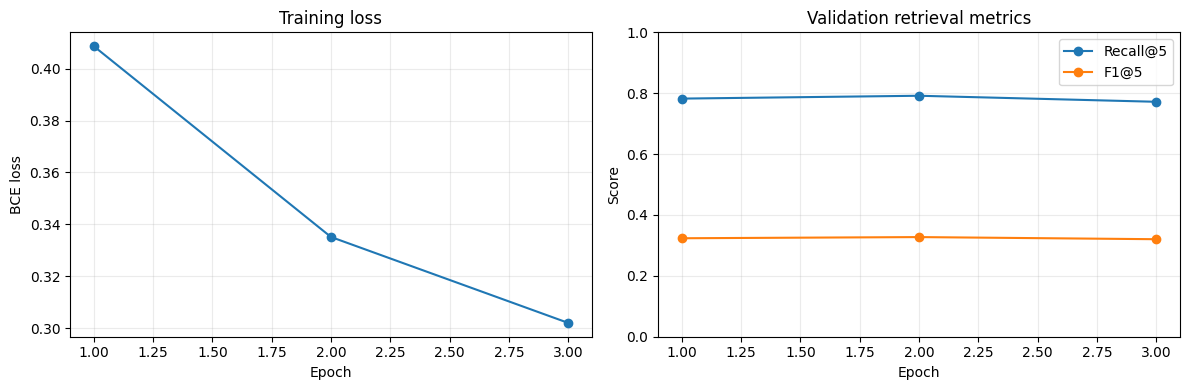

,headline,gold_tickers,top_candidates
0,What to know this week,"[AAPL, MSFT]","[{'ticker': 'AAPL', 'company': 'Apple Inc.', '..."
1,Yahoo Finance LIVE - Aug 29 PM,[AMZN],"[{'ticker': 'GOOGL', 'company': 'Alphabet Inc...."
2,What to know this week,"[MU, NFLX, TSLA]","[{'ticker': 'NFLX', 'company': 'Netflix, Inc.'..."
3,Yahoo Finance LIVE - Aug 29 AM,[AMZN],"[{'ticker': 'GOOGL', 'company': 'Alphabet Inc...."
4,Yahoo Finance LIVE - Sept 1 PM,[AMZN],"[{'ticker': 'GOOGL', 'company': 'Alphabet Inc...."


In [5]:
# Evaluate once on the held-out temporal test partition at several configurable K values.
test_similarity=score_frame(splits["test"])
metric_rows=[]
for k in EVALUATION_TOP_K:
    metric_rows.append({"model":"FLANG-RoBERTa Cosine Stock Selector","top_k":k,
                        **retrieval_metrics(splits["test"],test_similarity,k)})
metrics_df=pd.DataFrame(metric_rows)
print("Held-out stock retrieval metrics")
display(metrics_df.round(4))
metrics_df.to_csv(OUTPUT_DIR/"ticker_selector_metrics.csv",index=False)
history_df=pd.DataFrame(history)
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(history_df.epoch,history_df.train_loss,marker="o"); axes[0].set(title="Training loss",xlabel="Epoch",ylabel="BCE loss")
axes[1].plot(history_df.epoch,history_df[f"recall@{PRODUCTION_TOP_K}"],marker="o",label=f"Recall@{PRODUCTION_TOP_K}")
axes[1].plot(history_df.epoch,history_df[f"f1@{PRODUCTION_TOP_K}"],marker="o",label=f"F1@{PRODUCTION_TOP_K}")
axes[1].set(title="Validation retrieval metrics",xlabel="Epoch",ylabel="Score",ylim=(0,1)); axes[1].legend()
for ax in axes: ax.grid(alpha=.25)
fig.tight_layout(); fig.savefig(OUTPUT_DIR/"ticker_selector_metrics.png",dpi=160,bbox_inches="tight"); plt.show()

# Show candidate ranking and cosine score for held-out examples.
def rank_candidates(text,k=PRODUCTION_TOP_K):
    article_vec=embed_texts([str(text)])[0]
    profile_vec=embed_texts([TICKER_PROFILES[s] for s in CANDIDATE_TICKERS])
    cosine=profile_vec @ article_vec
    take=torch.topk(cosine,min(max(1,int(k)),len(CANDIDATE_TICKERS))).indices.tolist()
    return [{"ticker":CANDIDATE_TICKERS[i],"company":SP100_COMPANIES[CANDIDATE_TICKERS[i]],
             "cosine_similarity":float(cosine[i]),
             "relevance_score":float(torch.sigmoid(cosine[i]/COSINE_TEMPERATURE))} for i in take]
sample=[]
for _,row in splits["test"].head(5).iterrows():
    sample.append({"headline":row.title,"gold_tickers":row.gold_tickers,"top_candidates":rank_candidates(row.article)})
display(pd.DataFrame(sample))


## Export the Kaggle model

The export has a fine-tuned encoder, tokenizer, and `selector_config.json` with `backend=cosine_embedding`. The upload code targets `arjunverma14142/flang-roberta-stock-selector/pyTorch/default`; create that model variation on Kaggle first, then run the upload cell and set it Public in model settings.


In [6]:
MODEL_EXPORT_DIR=OUTPUT_DIR/"FLANG_RoBERTa_Stock_Selector"
MODEL_EXPORT_DIR.mkdir(parents=True,exist_ok=True)
encoder.save_pretrained(MODEL_EXPORT_DIR/"encoder",safe_serialization=True)
tokenizer.save_pretrained(MODEL_EXPORT_DIR/"tokenizer")
manifest={
    "model_name":"FLANG-RoBERTa Cosine Stock Selector",
    "base_model":BASE_MODEL,
    "backend":"cosine_embedding",
    "max_length":MAX_LENGTH,
    "production_top_k":PRODUCTION_TOP_K,
    "temperature":COSINE_TEMPERATURE,
    "candidate_universe":"SP100_COMPANIES",
    "pooling":"attention_masked_mean",
    "ranking":"cosine_similarity",
    "validation_checkpoint_metric":f"recall@{PRODUCTION_TOP_K}",
    "heldout_metrics":metric_rows,
    "ticker_classification_head":False,
}
(MODEL_EXPORT_DIR/"selector_config.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
metrics_df.to_csv(MODEL_EXPORT_DIR/"heldout_metrics.csv",index=False)
import shutil
zip_path=Path(shutil.make_archive("/kaggle/working/flang_roberta_stock_selector_bundle","zip",root_dir=OUTPUT_DIR))
print("Kaggle Model upload directory:",MODEL_EXPORT_DIR)
print("Downloadable model bundle:",zip_path)
for path in sorted(MODEL_EXPORT_DIR.rglob("*")):
    if path.is_file(): print(path.relative_to(MODEL_EXPORT_DIR),f"{path.stat().st_size/1e6:.1f} MB")


Kaggle Model upload directory: /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector
Downloadable model bundle: /kaggle/working/flang_roberta_stock_selector_bundle.zip
encoder/config.json 0.0 MB
encoder/model.safetensors 539.6 MB
heldout_metrics.csv 0.0 MB
selector_config.json 0.0 MB
tokenizer/added_tokens.json 0.0 MB
tokenizer/bpe.codes 1.1 MB
tokenizer/special_tokens_map.json 0.0 MB
tokenizer/tokenizer_config.json 0.0 MB
tokenizer/vocab.txt 0.8 MB


In [7]:
# Create this model under arjunverma14142 on Kaggle Models before running this upload cell.
# Kaggle model handles are public only after you set Settings -> Visibility -> Public on the model page.
%pip -q install -U kagglehub
import kagglehub
MODEL_HANDLE="arjunverma14142/flang-roberta-stock-selector/pyTorch/default"
kagglehub.model_upload(
    handle=MODEL_HANDLE,
    local_model_dir=str(MODEL_EXPORT_DIR),
    version_notes=f"Cosine article/company FLANG-RoBERTa stock selector; top-K={PRODUCTION_TOP_K}; temporal held-out metrics included."
)
print("Uploaded model variation:",MODEL_HANDLE)


Note: you may need to restart the kernel to use updated packages.
Uploading Model https://kaggle.com/models/arjunverma14142/flang-roberta-stock-selector/pyTorch/default ...
Model 'flang-roberta-stock-selector' does not exist or access is forbidden for user 'arjunverma14142'. Creating or handling Model...
Model 'flang-roberta-stock-selector' Created.
Starting upload for file /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/heldout_metrics.csv


Uploading: 100%|██████████| 823/823 [00:00<00:00, 1.72kB/s]

Upload successful: /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/heldout_metrics.csv (823B)
Starting upload for file /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/selector_config.json



Uploading: 100%|██████████| 1.64k/1.64k [00:00<00:00, 3.76kB/s]

Upload successful: /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/selector_config.json (2KB)
Starting upload for file /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/tokenizer/special_tokens_map.json


...


Uploading: 100%|██████████| 540M/540M [00:08<00:00, 61.6MB/s]

Upload successful: /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/encoder/model.safetensors (515MB)
Starting upload for file /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/encoder/config.json



Uploading: 100%|██████████| 702/702 [00:00<00:00, 1.62kB/s]

Upload successful: /kaggle/working/flang_roberta_stock_selector/FLANG_RoBERTa_Stock_Selector/encoder/config.json (702B)


Your model instance has been created.
Files are being processed...
See at: https://kaggle.com/models/arjunverma14142/flang-roberta-stock-selector/pyTorch/default
Uploaded model variation: arjunverma14142/flang-roberta-stock-selector/pyTorch/default


## Reload and tune top-K

The backend's production K is configured in `src/backend/constants.py` as `STOCK_SELECTOR_TOP_K`; change that constant without retraining to tune the candidate shortlist.


In [8]:
# The backend loader uses this same model bundle format; top-K remains tunable independently.
def load_stock_selector(model_dir,device=DEVICE):
    model_dir=Path(model_dir)
    manifest=json.loads((model_dir/"selector_config.json").read_text(encoding="utf-8"))
    loaded_encoder=AutoModel.from_pretrained(model_dir/"encoder",local_files_only=True).to(device).eval()
    loaded_tokenizer=AutoTokenizer.from_pretrained(model_dir/"tokenizer",local_files_only=True)
    return loaded_encoder,loaded_tokenizer,manifest

@torch.inference_mode()
def predict_stock_candidates(text,loaded_encoder,loaded_tokenizer,k=PRODUCTION_TOP_K,device=DEVICE):
    profiles=[f"Stock ticker: {s}. Company: {SP100_COMPANIES[s]}." for s in CANDIDATE_TICKERS]
    def embed(texts):
        vectors=[]
        for start in range(0,len(texts),EMBED_BATCH_SIZE):
            tokens=loaded_tokenizer(texts[start:start+EMBED_BATCH_SIZE],truncation=True,max_length=MAX_LENGTH,padding=True,return_tensors="pt")
            tokens={name:value.to(device) for name,value in tokens.items()}
            hidden=loaded_encoder(**tokens).last_hidden_state
            mask=tokens["attention_mask"].unsqueeze(-1).to(hidden.dtype)
            pooled=(hidden*mask).sum(1)/mask.sum(1).clamp(min=1)
            vectors.append(torch.nn.functional.normalize(pooled.float(),p=2,dim=-1))
        return torch.cat(vectors)
    article_vector=embed([str(text)])[0]
    profile_vectors=embed(profiles)
    cosine=profile_vectors@article_vector
    indexes=torch.topk(cosine,min(max(1,int(k)),len(CANDIDATE_TICKERS))).indices.tolist()
    return [{"ticker":CANDIDATE_TICKERS[i],"company":SP100_COMPANIES[CANDIDATE_TICKERS[i]],
             "cosine_similarity":float(cosine[i]),"relevance_score":float(torch.sigmoid(cosine[i]/COSINE_TEMPERATURE))}
            for i in indexes]

# Local bundle smoke example after training:
# loaded_encoder,loaded_tokenizer,selector_config=load_stock_selector(MODEL_EXPORT_DIR)
# predict_stock_candidates("Company headline and article text...",loaded_encoder,loaded_tokenizer,k=3)
